# Task 3.3 - Clustering       
Goal: Perform K-means clustering (from sratch) to cluster seeds into different goups.         
Deadline: 28th December.     

In [87]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

In [88]:
data = pd.read_csv('seeds_data.csv')
features_names = ['Feature_1','Feature_2','Feature_3','Feature_4','Feature_5','Feature_6','Feature_7']
features = data[features_names].values
labels = data['Class'].values
print(f"Features shape : {features.shape}")
print(f"Labels shape : {labels.shape}")

Features shape : (210, 7)
Labels shape : (210,)


In [89]:
features = (features - features.mean(axis=0)) / features.std(axis=0)

In [90]:
# Euclidean distance
def distance(a, b):
    return np.linalg.norm(a - b, axis=1)

In [91]:
# K-Means from scratch
# -------------------------
def kmeans(X, k, max_iters=100):
    # Step 1: initialize centroids randomly
    np.random.seed(42)
    indices = np.random.choice(len(X), k, replace=False)
    centroids = X[indices]

    for _ in range(max_iters):
        # Step 2: assign clusters
        clusters = [np.argmin([np.linalg.norm(x - c) for c in centroids]) for x in X]

        # Step 3: update centroids
        new_centroids = np.array([X[np.array(clusters) == i].mean(axis=0) for i in range(k)])

        # Stop if converged (no change)
        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return np.array(clusters), centroids

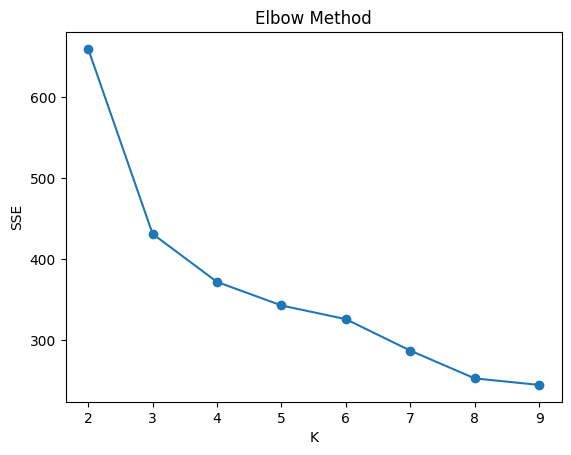

In [92]:
sse = []
K_range = range(2, 10)

for k in K_range:
    clusters, centers = kmeans(features, k)
    sse.append(sum(np.linalg.norm(features[i] - centers[clusters[i]])**2 for i in range(len(features))))

import matplotlib.pyplot as plt
plt.plot(K_range, sse, marker='o')
plt.xlabel("K")
plt.ylabel("SSE")
plt.title("Elbow Method")
plt.show()


In [ ]:
k_optimal = 3  # based on elbow
clusters, centers = kmeans(features, k_optimal)

print("\nCluster Centers:")
print(pd.DataFrame(centers))


Cluster Centers:
          0         1         2         3         4         5         6
0 -0.193294 -0.225932  0.420554 -0.320423 -0.039922 -0.688656 -0.653717
1 -1.037052 -1.011377 -0.992035 -0.893892 -1.104154  0.786772 -0.597248
2  1.226522  1.235749  0.532724  1.219935  1.130388 -0.046792  1.280207


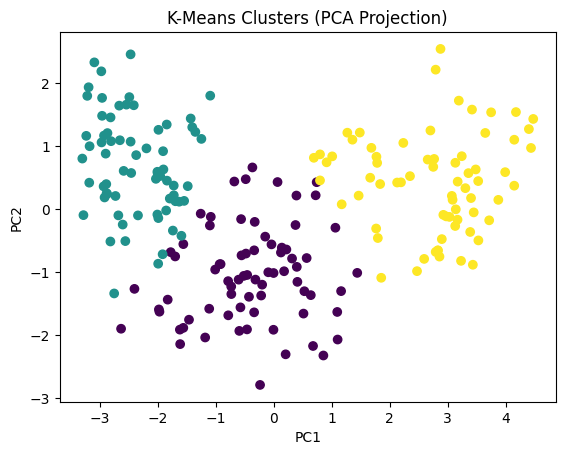

In [94]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_2d = pca.fit_transform(features)

plt.scatter(X_2d[:,0], X_2d[:,1], c=clusters, cmap="viridis")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("K-Means Clusters (PCA Projection)")
plt.show()

In [95]:
from sklearn.metrics import adjusted_rand_score, confusion_matrix

print("ARI:", adjusted_rand_score(labels, clusters))
print("Confusion Matrix:")
print(confusion_matrix(labels, clusters))


ARI: 0.8227344478849459
Confusion Matrix:
[[ 0  0  0  0]
 [65  3  2  0]
 [ 3  0 67  0]
 [ 5 65  0  0]]


In [96]:
from scipy.optimize import linear_sum_assignment as linear_assignment

# Map cluster labels to actual labels
mapping = {}
for cluster in range(k):
    mask = (clusters == cluster)
    true_labels = labels[mask]
    if len(true_labels) > 0:
        mapping[cluster] = np.bincount(true_labels).argmax()

# Create new predicted labels aligned with true classes
aligned_preds = np.vectorize(mapping.get)(clusters)

print("New ARI:", adjusted_rand_score(labels, aligned_preds))
print("Confusion Matrix:\n", confusion_matrix(labels, aligned_preds))


New ARI: 0.8227344478849459
Confusion Matrix:
 [[65  2  3]
 [ 3 67  0]
 [ 5  0 65]]
